## Treinamento dos modelos e otimização dos hiperparâmetros

Nessa etapa, realizaremos o treinamento dos modelos com base nos dados para os diferentes datasets armazenados na etapa anterior.

Essa etapa será baseada no framework de rastreamento de experimentos [TrailKeeper](https://github.com/MauricioSight/TrailKeeper), que foi implementada de maneira mais simplificada em `../models/`, mas ainda preservando as camadas e o rastreamento usando uma conexão com o *Weights & Biases* e otimização de hiperparâmetros com o *Optuna*.

In [1]:
import sys
sys.path.append("../models")

from carregar_dados import DATASETS
from modelos import MODELOS
from experimento import rodar
from otimizar import otimizar

### Modelos com parâmetros padrão

Primeiro treinamos todos os modelos de `modelos.py` com seus parâmetros padrão, nos dois datasets. Isso dá um ponto de comparação para a otimização e o baseline mostra o mínimo que precisamos superar.

Os algoritmos escolhidos foram:
* Regressão Linear para o baseline
* ElasticNet (regressão linear com regularização L1 e L2)
* Histogram-based Gradient Boosting Regressor (implementação do Scikit-Learn para o LightGBM)
* Random Forest Regressor

In [2]:
res = []

for ds in DATASETS:
    for m in MODELOS.keys():
        r = rodar(m, dataset=ds)
        res.append({
            "modelo": m,
            "dataset": ds,
            "run_id": r["run_id"],
            **r['validacao']
        })


wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /home/user/.netrc.


[baseline_imputado_20261127_194711_411100] validação: rmse_log=1.3224  mae_log=1.0427  r2_log=0.5727  rmse=178.0620  mae=62.7485  r2=0.3469
[elasticnet_imputado_20261127_194741_541565] validação: rmse_log=1.2041  mae_log=0.9002  r2_log=0.6457  rmse=142.9777  mae=52.2870  r2=0.5789
[hgb_imputado_20261127_194747_854849] validação: rmse_log=1.1975  mae_log=0.8892  r2_log=0.6496  rmse=107.6538  mae=42.6925  r2=0.7613
[random_forest_imputado_20261127_194755_646724] validação: rmse_log=1.2118  mae_log=0.8875  r2_log=0.6412  rmse=110.1902  mae=42.9683  r2=0.7499
[baseline_sem_faltantes_20261127_194816_318313] validação: rmse_log=1.1770  mae_log=1.0014  r2_log=0.5197  rmse=251.2768  mae=113.6488  r2=0.1842
[elasticnet_sem_faltantes_20261127_194820_989916] validação: rmse_log=0.9232  mae_log=0.7663  r2_log=0.7045  rmse=199.7705  mae=91.4993  r2=0.4844
[hgb_sem_faltantes_20261127_194825_407448] validação: rmse_log=0.8698  mae_log=0.6975  r2_log=0.7377  rmse=168.4432  mae=72.4449  r2=0.6334
[rand

In [3]:
import pandas as pd

padrao = pd.DataFrame(res).sort_values(["dataset", "rmse"]).reset_index(drop=True)
padrao

,modelo,dataset,run_id,rmse_log,mae_log,r2_log,rmse,mae,r2
0,hgb,imputado,hgb_imputado_20261127_194747_854849,1.197531,0.889158,0.649595,107.653770,42.692503,0.761272
1,random_forest,imputado,random_forest_imputado_20261127_194755_646724,1.211824,0.887483,0.641180,110.190151,42.968318,0.749891
2,elasticnet,imputado,elasticnet_imputado_20261127_194741_541565,1.204119,0.900200,0.645729,142.977661,52.287049,0.578905
3,baseline,imputado,baseline_imputado_20261127_194711_411100,1.322371,1.042740,0.572729,178.061995,62.748524,0.346890
4,hgb,sem_faltantes,hgb_sem_faltantes_20261127_194825_407448,0.869790,0.697488,0.737712,168.443225,72.444881,0.633394
5,random_forest,sem_faltantes,random_forest_sem_faltantes_20261127_194831_68...,0.813958,0.649181,0.770304,181.544033,77.506772,0.574151
6,elasticnet,sem_faltantes,elasticnet_sem_faltantes_20261127_194820_989916,0.923241,0.766307,0.704484,199.770507,91.499335,0.484350
7,baseline,sem_faltantes,baseline_sem_faltantes_20261127_194816_318313,1.177004,1.001369,0.519707,251.276790,113.648824,0.184175


### Otimização dos hiperparâmetros

Com o *Optuna*, buscamos os melhores hiperparâmetros dos modelos que têm espaço de busca definido em `modelos.py` para o `elasticnet`, `hgb` e `random_forest`. O `baseline` não tem hiperparâmetros para otimizar.

Cada trial vira uma run no *W&B*, agrupadas por otimização, e a escolha do melhor é feita pelo RMSE de validação (em unidades de demanda).

In [4]:
MODELOS_OTIMIZAVEIS = [m for m, cfg in MODELOS.items() if callable(cfg.get("espaco"))]
N_TRIALS = 20

estudos = {}

for ds in DATASETS:
    for m in MODELOS_OTIMIZAVEIS:
        estudos[(m, ds)] = otimizar(m, n_trials=N_TRIALS, metrica="rmse", dataset=ds)

✔ elasticnet · imputado — 20 trials em 152s | melhor rmse: 110.48 (trial 11)
  alpha=0.003604, l1_ratio=0.4233

/home/user/Desktop/Predicao-Demanda/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.277776e+00, tolerance: 9.634e-01
  model = cd_fast.enet_coordinate_descent(
/home/user/Desktop/Predicao-Demanda/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.379563e+01, tolerance: 9.634e-01
  model = cd_fast.enet_coordinate_descent(


✔ hgb · imputado — 20 trials em 168s | melhor rmse: 104.48 (trial 10)
  max_depth=3, learning_rate=0.02887, max_iter=450, min_samples_leaf=35, l2_regularization=0.005488

✔ random_forest · imputado — 20 trials em 444s | melhor rmse: 108.34 (trial 14)
  n_estimators=300, max_depth=6, max_features=0.8865

✔ elasticnet · sem_faltantes — 20 trials em 68s | melhor rmse: 154.85 (trial 10)
  alpha=0.01445, l1_ratio=0.3267

/home/user/Desktop/Predicao-Demanda/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.719687e+00, tolerance: 1.286e-01
  model = cd_fast.enet_coordinate_descent(
/home/user/Desktop/Predicao-Demanda/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.229462e+01, tolerance: 1.286e-01
  model = cd_fast.enet_coordinate_descent(
/home/user/Desktop/Predicao-Demanda/.venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the sca

✔ hgb · sem_faltantes — 20 trials em 77s | melhor rmse: 159.78 (trial 19)
  max_depth=3, learning_rate=0.03585, max_iter=550, min_samples_leaf=56, l2_regularization=0.04105

✔ random_forest · sem_faltantes — 20 trials em 122s | melhor rmse: 180.03 (trial 13)
  n_estimators=500, max_depth=12, max_features=0.7782

### Comparação dos melhores trials

Reunimos o melhor trial de cada modelo e dataset. O `run_id` identifica a pasta em `models/runs/`, que guarda os pesos do modelo em `modelo.joblib` e o `config.json` daquela run.

In [5]:
melhores = pd.DataFrame([
    {
        "modelo": m,
        "dataset": ds,
        "rmse_val": e.best_value,
        "run_id": e.best_trial.user_attrs["run_id"],
        "params": e.best_params,
    }
    for (m, ds), e in estudos.items()
]).sort_values(["dataset", "rmse_val"], ascending=True).reset_index(drop=True)

melhores

,modelo,dataset,rmse_val,run_id,params
0,hgb,imputado,104.481244,hgb_imputado_20261127_195204_430739,"{'max_depth': 3, 'learning_rate': 0.0288692203..."
1,random_forest,imputado,108.340407,random_forest_imputado_20261127_195953_540830,"{'n_estimators': 300, 'max_depth': 6, 'max_fea..."
2,elasticnet,imputado,110.484857,elasticnet_imputado_20261127_195031_193068,"{'alpha': 0.0036035178201071763, 'l1_ratio': 0..."
3,elasticnet,sem_faltantes,154.854079,elasticnet_sem_faltantes_20261127_200157_939204,"{'alpha': 0.01444525102276306, 'l1_ratio': 0.3..."
4,hgb,sem_faltantes,159.783944,hgb_sem_faltantes_20261127_200342_951937,"{'max_depth': 3, 'learning_rate': 0.0358486003..."
5,random_forest,sem_faltantes,180.027902,random_forest_sem_faltantes_20261127_200503_49...,"{'n_estimators': 500, 'max_depth': 12, 'max_fe..."


In [12]:
# Otimizado vs. parâmetros padrão (RMSE de validação, em unidades)
comparacao = melhores.merge(
    padrao[["modelo", "dataset", "rmse"]].rename(columns={"rmse": "rmse_padrao"}),
    on=["modelo", "dataset"],
)
comparacao["ganho_%"] = 100 * (comparacao["rmse_padrao"] - comparacao["rmse_val"]) / comparacao["rmse_padrao"]

comparacao[["modelo", "dataset", "rmse_padrao", "rmse_val", "ganho_%"]]

,modelo,dataset,rmse_padrao,rmse_val,ganho_%
0,hgb,imputado,107.653770,104.481244,2.946971
1,random_forest,imputado,110.190151,108.340407,1.678684
2,elasticnet,imputado,142.977661,110.484857,22.725791
3,elasticnet,sem_faltantes,199.770507,154.854079,22.484014
4,hgb,sem_faltantes,168.443225,159.783944,5.140771
5,random_forest,sem_faltantes,181.544033,180.027902,0.835131


### Visualização dos resultados

Primeiro, o RMSE de validação de cada modelo com os parâmetros padrão e depois da otimização. A linha tracejada é o baseline. Os datasets ficam em gráficos separados, com escalas próprias, porque os conjuntos de validação são diferentes.

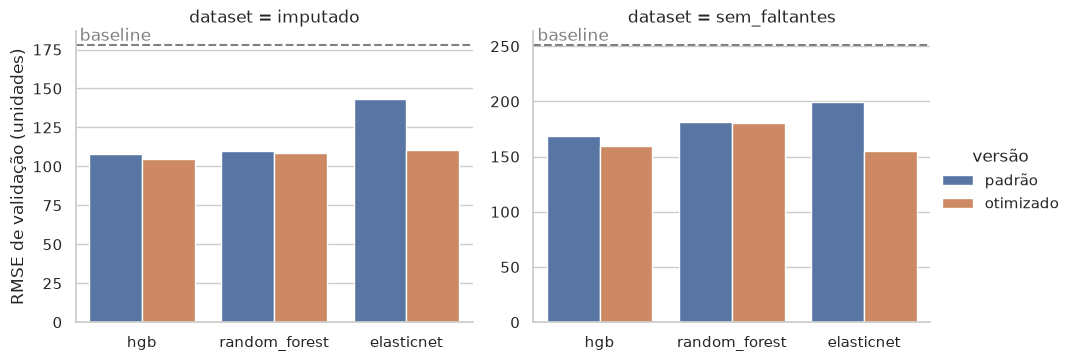

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

dados = comparacao.melt(id_vars=["modelo", "dataset"], value_vars=["rmse_padrao", "rmse_val"],
                        var_name="versão", value_name="rmse")
dados["versão"] = dados["versão"].map({"rmse_padrao": "padrão", "rmse_val": "otimizado"})

g = sns.catplot(data=dados, x="modelo", y="rmse", hue="versão", col="dataset",
                kind="bar", sharey=False, height=4, aspect=1.2)
g.set_axis_labels("", "RMSE de validação (unidades)")

baseline = padrao[padrao["modelo"] == "baseline"].set_index("dataset")["rmse"]
for ds, ax in g.axes_dict.items():
    ax.axhline(baseline[ds], color="gray", linestyle="--")
    ax.text(0.01, baseline[ds], "baseline", color="gray", va="bottom", transform=ax.get_yaxis_transform())

plt.show()

Evolução da busca: o melhor RMSE encontrado até cada trial. Curvas que ainda caem no fim indicam que mais trials poderiam melhorar o resultado.

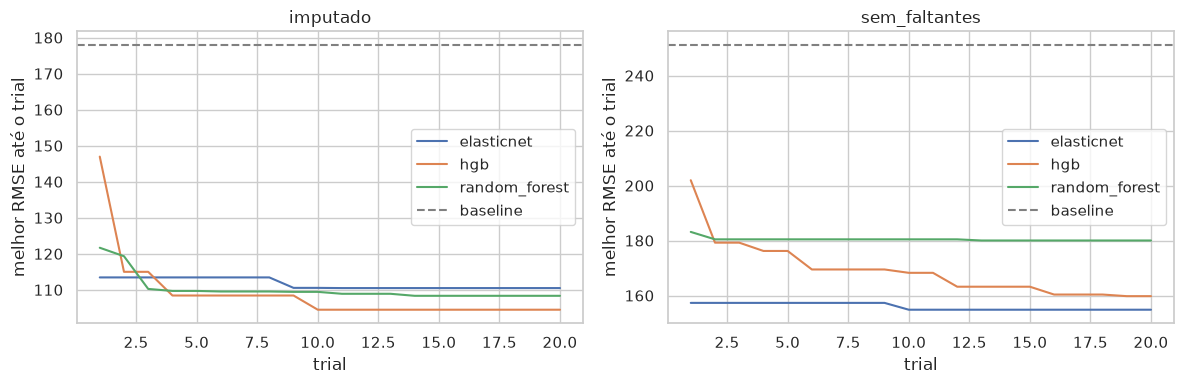

In [8]:
fig, eixos = plt.subplots(1, len(DATASETS), figsize=(12, 4))

for eixo, ds in zip(eixos, DATASETS):
    for (m, d), estudo in estudos.items():
        if d == ds:
            melhor_ate_agora = pd.Series([t.value for t in estudo.trials]).cummin()   # rmse: menor é melhor
            eixo.plot(range(1, len(melhor_ate_agora) + 1), melhor_ate_agora, label=m)
    eixo.axhline(baseline[ds], color="gray", linestyle="--", label="baseline")
    eixo.set(title=ds, xlabel="trial", ylabel="melhor RMSE até o trial")
    eixo.legend()

plt.tight_layout()
plt.show()

Por fim, analisamos a importância dos hiperparâmetros por modelo e por dataset, que indica o quanto cada hiperparâmetro contribuiu para a variação do desempenho (no nosso caso, o RMSE de validação) ao longo de todas as tentativas realizadas pelo Optuna.

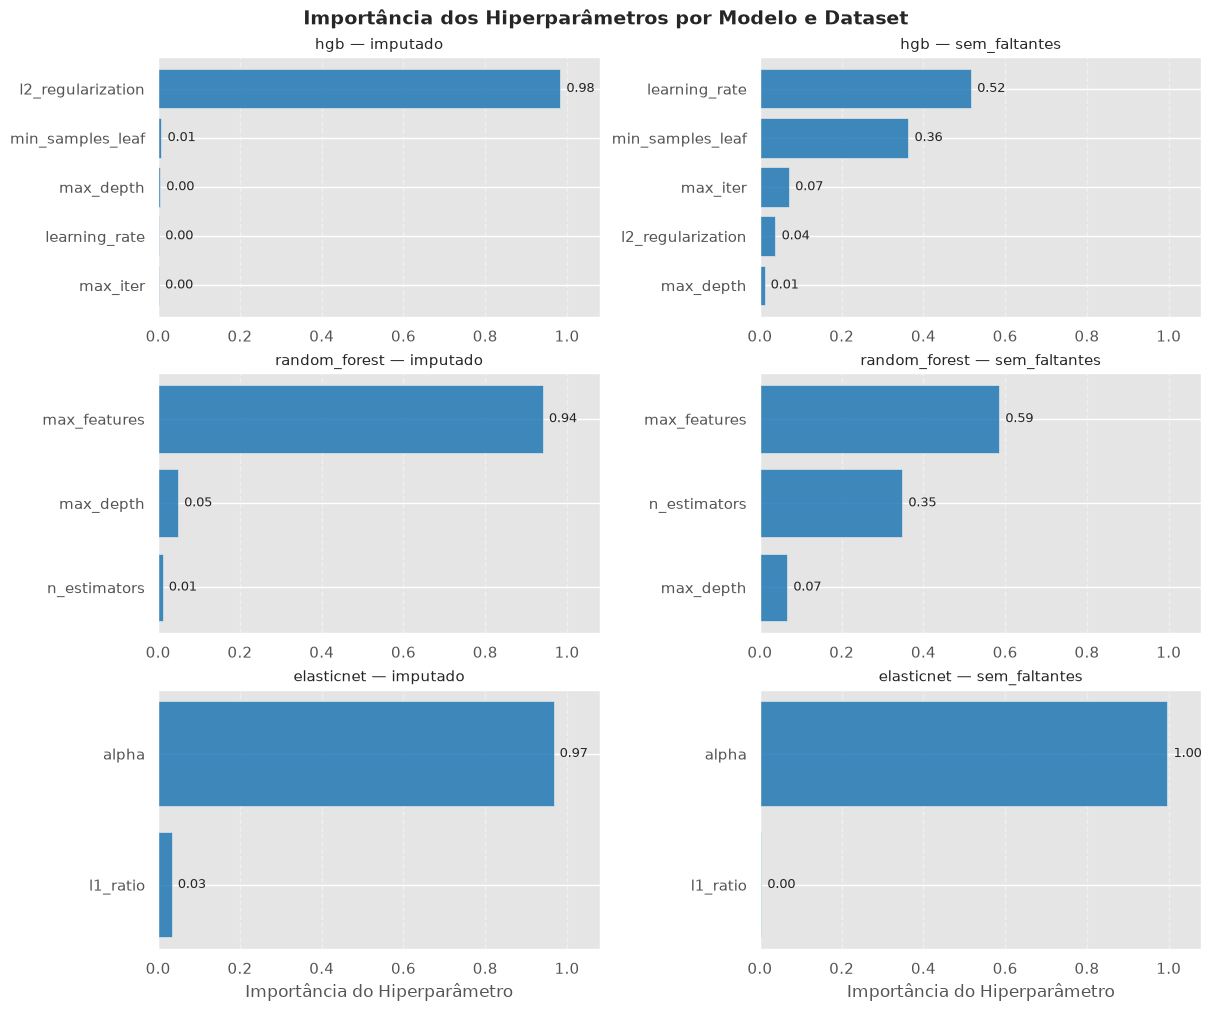

In [19]:
from optuna.importance import get_param_importances

modelos = ["hgb", "random_forest", "elasticnet"]
datasets = ["imputado", "sem_faltantes"]

fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 10), constrained_layout=True)

for i, modelo in enumerate(modelos):
    for j, dataset in enumerate(datasets):
        ax = axes[i, j]
        estudo = estudos[(modelo, dataset)]
        importancias = get_param_importances(estudo)
        
        params = list(importancias.keys())[::-1]
        valores = list(importancias.values())[::-1]
        
        # Plota as barras horizontais
        bars = ax.barh(params, valores, color="#1f77b4", alpha=0.85)
        ax.set_title(f"{modelo} — {dataset}", fontsize=11)
        ax.set_xlim(0, 1.08) # Vai de 0 a 1 (100% da importância) com folga para o texto
        ax.grid(axis="x", linestyle="--", alpha=0.4)
        
        for bar in bars:
            largura = bar.get_width()
            ax.text(
                largura + 0.015,
                bar.get_y() + bar.get_height() / 2,
                f"{largura:.2f}",
                va="center",
                fontsize=9
            )

        # Mostra o rótulo do eixo X apenas na última linha para limpar o visual
        if i == len(modelos) - 1:
            ax.set_xlabel("Importância do Hiperparâmetro")

fig.suptitle("Importância dos Hiperparâmetros por Modelo e Dataset", fontsize=14, fontweight="bold")
plt.show()
